# 03 - Intrinsic and rolling intrinsic value

The storage contract (1 TWh working volume, 150 days to fill, 100 days to empty, ratchets, illustrative
costs) is valued over storage year 2027/28 in two steps of increasing optionality:

1. **Intrinsic value**: the best injection / withdrawal schedule locked in today against the forward curve.
2. **Rolling intrinsic value**: the same optimisation re-run every month along simulated paths of the
   one-factor model (notebook 02), trading the schedule changes. It captures forward-curve moves.

Notebook 04 adds the full spot optionality with Least-Squares Monte Carlo.

### Two forward curves, on purpose

| | Market case (`storage_default.yaml`) | Contango case (`storage_synthetic.yaml`) |
|---|---|---|
| Curve | EEX TTF settlements of 2026-11-17 | **SYNTHETIC** seasonal curve |
| Shape over 2027/28 | strictly decreasing (backwardation) | summer trough, winter peak, contango |
| What it shows | the value a desk would actually book today | how storage is "supposed" to make money |

The **market case** is the real answer: storage year 2027/28 is priced in seasonal backwardation (summer gas is bid
up to refill low European stocks), so no calendar spread is profitable and the intrinsic value is **zero**. All of
the storage value is then extrinsic, i.e. pure optionality on future price moves. That is an interesting result in
itself, but it hides most of the machinery: a zero schedule cannot illustrate the LP / DP cross-check, the shape of
an optimal fill profile or the intrinsic / extrinsic split. The **contango case** keeps the same contract and model
on a textbook curve with a summer-winter spread, where all of those are visible. Its numbers are illustrative only.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.models.one_factor import OneFactorModel
from gasstorage.storage.contract import build_inputs
from gasstorage.storage.dp import solve_dp
from gasstorage.storage.intrinsic import solve_lp
from gasstorage.storage.rolling_intrinsic import rolling_intrinsic

plotting.apply_style()
CASES = {
    "market (EEX)": "configs/storage_default.yaml",
    "contango (SYNTHETIC)": "configs/storage_synthetic.yaml",
}
cfgs = {name: load_config(path) for name, path in CASES.items()}
c = cfgs["market (EEX)"].contract
pd.Series(
    {
        "working volume (MWh)": c.working_volume_mwh,
        "max injection (MWh/day)": c.max_injection_mwh_per_day,
        "max withdrawal (MWh/day)": c.max_withdrawal_mwh_per_day,
        "injection ratchet": "x0.6 above 70 % fill",
        "withdrawal ratchet": "x0.5 below 30 % fill",
        "costs (EUR/MWh)": f"{c.injection_cost_eur_mwh} in, {c.withdrawal_cost_eur_mwh} out",
        "discount rate": cfgs["market (EEX)"].market.discount_rate,
    },
    name="contract (illustrative)",
).to_frame()

,contract (illustrative)
working volume (MWh),1000000.0
max injection (MWh/day),6666.666667
max withdrawal (MWh/day),10000.0
injection ratchet,x0.6 above 70 % fill
withdrawal ratchet,x0.5 below 30 % fill
costs (EUR/MWh),"0.5 in, 0.5 out"
discount rate,0.03


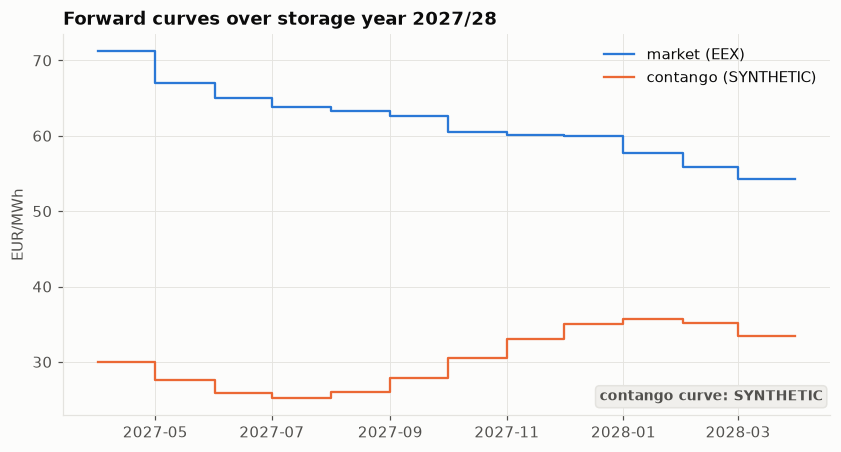

In [2]:
fig, ax = plt.subplots()
for color, (name, cfg) in zip(plotting.SERIES, cfgs.items(), strict=False):
    inp = build_inputs(cfg, "daily")
    ax.step(inp.dates, inp.prices, where="post", color=color, label=name)
ax.set_ylabel("EUR/MWh")
ax.set_title("Forward curves over storage year 2027/28")
ax.legend(loc="upper right")
plotting.mark_synthetic(ax, "contango curve: SYNTHETIC", corner="lower right")
plotting.save_figure(fig, "03_curves")
fig

## 1. Intrinsic value: LP, MILP and DP

$$V^{\text{int}} = \max_{i,w\ge0} \sum_k D_k\Big[(F_k - c^{\text{wdr}})w_k - \big(F_k(1+\lambda) + c^{\text{inj}}\big)i_k\Big]$$

subject to $v_{k+1} = v_k + i_k - w_k$, $0\le v_k\le\bar V$, $v_0 = v_K = 0$ and the rate limits
$i_k \le q^{\text{inj}}d_k\phi^{\text{inj}}(v_k/\bar V)$, $w_k \le q^{\text{wdr}}d_k\phi^{\text{wdr}}(v_k/\bar V)$.

* **LP** (cvxpy + HiGHS) with nominal rates: exact without ratchets, an upper bound with them.
* **MILP**: binary tier variables make the ratchets exact (formulation in `gasstorage.storage.intrinsic`).
* **DP** on a volume grid with linearly interpolated continuation (`gasstorage.storage.dp`): the cross-check,
  and the engine reused by the rolling intrinsic and LSMC policies.

Ratchets are applied to the start-of-step fill level: exact for daily steps, an approximation for weekly steps.

In [3]:
rows = []
for name, cfg in cfgs.items():
    for step in ("weekly", "daily"):
        inp = build_inputs(cfg, step)
        k = inp.contract
        t0 = time.perf_counter()
        milp = solve_lp(k, inp.prices, inp.days, inp.discount, ratchets=True)
        t_milp = time.perf_counter() - t0
        row = {
            "case": name,
            "step": step,
            "LP no ratchets": solve_lp(
                k.without_ratchets(), inp.prices, inp.days, inp.discount
            ).value,
            "DP no ratchets (G=101)": solve_dp(
                k.without_ratchets(), inp.prices, inp.days, inp.discount
            ).value,
            "MILP ratchets": milp.value,
            "DP ratchets (G=101)": solve_dp(
                k, inp.prices, inp.days, inp.discount, n_levels=101
            ).value,
            "DP ratchets (G=1001)": solve_dp(
                k, inp.prices, inp.days, inp.discount, n_levels=1001
            ).value,
            "MILP time (s)": t_milp,
        }
        rows.append(row)
intrinsic = pd.DataFrame(rows).set_index(["case", "step"])
(intrinsic / 1e6).round(4).rename(columns=lambda s: s if "time" in s else s + " [MEUR]").assign(
    **{"MILP time (s)": intrinsic["MILP time (s)"].round(2)}
)

LP no ratchets [MEUR]  \
case                 step                            
market (EEX)         weekly                 0.0000   
                     daily                  0.0000   
contango (SYNTHETIC) weekly                 6.9662   
                     daily                  6.9807   

                             DP no ratchets (G=101) [MEUR]  \
case                 step                                    
market (EEX)         weekly                         0.0000   
                     daily                          0.0000   
contango (SYNTHETIC) weekly                         6.9651   
                     daily                          6.9794   

                             MILP ratchets [MEUR]  DP ratchets (G=101) [MEUR]  \
case                 step                                                       
market (EEX)         weekly                0.0000                      0.0000   
                     daily                 0.0000                      0.0000   
contango (SYNTHETIC) weekly                6.5395                      6.4343   
                     daily                 6.4024                      5.9570   

                             DP ratchets (G=1001) [MEUR]  MILP time (s)  
case                 step                                                
market (EEX)         weekly                       0.0000           0.09  
                     daily                        0.0000           0.18  
contango (SYNTHETIC) weekly                       6.5364           0.34  
                     daily                        6.3981           2.22

**Cross-checks.**

* Without ratchets the LP and the DP agree to the grid discretisation (the DP policy is feasible for the LP, so it is
  never above it).
* With ratchets the DP converges to the MILP from below as the grid is refined. Tier ratchets make the value function
  discontinuous at tier boundaries: the MILP can stop just below 70 % fill to keep the full injection rate one more
  step, the grid only at the level below. The error is $O(\Delta)$, larger on the daily grid where a day of injection
  (6,667 MWh) is smaller than a 101-level grid step (10,000 MWh).

In [4]:
inp_w = build_inputs(cfgs["contango (SYNTHETIC)"], "weekly")
k = inp_w.contract
milp_w = solve_lp(k, inp_w.prices, inp_w.days, inp_w.discount, ratchets=True).value
conv = pd.DataFrame(
    {
        g: {
            "DP value [MEUR]": solve_dp(
                k, inp_w.prices, inp_w.days, inp_w.discount, n_levels=g
            ).value
            / 1e6
        }
        for g in (26, 51, 101, 201, 401, 1001)
    }
).T
conv["gap to MILP (%)"] = 100 * (conv["DP value [MEUR]"] * 1e6 / milp_w - 1)
conv.index.name = "grid levels G"
print(f"MILP (weekly, contango): {milp_w / 1e6:.4f} MEUR")
conv.round(4)

MILP (weekly, contango): 6.5395 MEUR


,DP value [MEUR],gap to MILP (%)
grid levels G,,
26,5.6457,-13.6679
51,6.2259,-4.7962
101,6.4343,-1.6085
201,6.5208,-0.2862
401,6.5317,-0.1198
1001,6.5364,-0.0476


## 2. Optimal intrinsic schedules

Daily MILP schedules. In the contango case the storage fills from late spring, slows down above 70 % (injection
ratchet), sits full until the winter peak and empties through January-March, slowing below 30 % (withdrawal ratchet).
In the market case the optimal schedule is to do nothing.

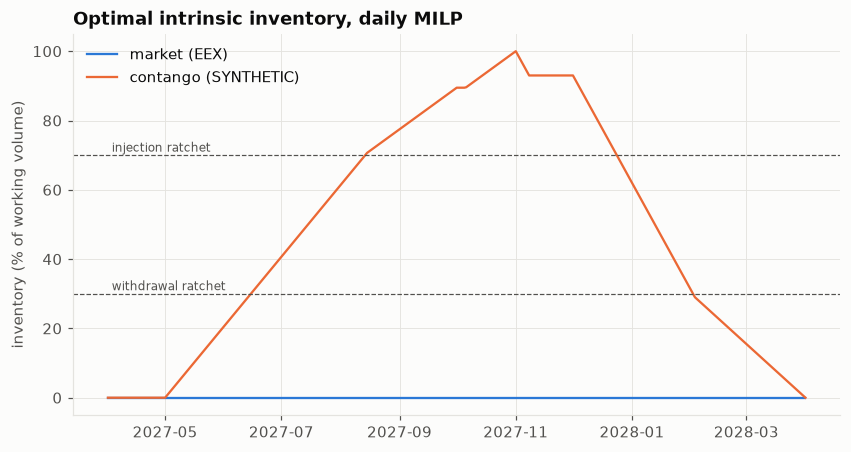

In [5]:
fig, ax = plt.subplots()
schedules = {}
for color, (name, cfg) in zip(plotting.SERIES, cfgs.items(), strict=False):
    inp = build_inputs(cfg, "daily")
    res = solve_lp(inp.contract, inp.prices, inp.days, inp.discount, ratchets=True)
    schedules[name] = res
    dates = inp.dates.append(pd.DatetimeIndex([inp.dates[-1] + pd.Timedelta(days=1)]))
    ax.plot(dates, 100 * res.inventory / inp.contract.working_volume, color=color, label=name)
ax.axhline(70, color=plotting.TEXT_SECONDARY, lw=0.8, ls="--")
ax.axhline(30, color=plotting.TEXT_SECONDARY, lw=0.8, ls="--")
ax.text(dates[2], 71, "injection ratchet", fontsize=8, color=plotting.TEXT_SECONDARY)
ax.text(dates[2], 31, "withdrawal ratchet", fontsize=8, color=plotting.TEXT_SECONDARY)
ax.set_ylabel("inventory (% of working volume)")
ax.set_title("Optimal intrinsic inventory, daily MILP")
ax.legend(loc="upper left")
plotting.save_figure(fig, "03_intrinsic_schedule")
fig

## 3. Rolling intrinsic

Along each simulated path, the intrinsic problem is re-solved on the first decision date of every month from the
current inventory, against the model-implied forward curve of that path,
$F(t_k,t_j) = F(0,t_j)\exp\big(e^{-\kappa(t_j-t_k)}X_{t_k} + \tfrac12 V(t_k,t_j) - \tfrac12 V(0,t_j)\big)$,
and the schedule is followed until the next month; volumes settle at the spot $S_{t_k}$. Weekly steps, 101-level grid,
2,000 paths, fixed seed; the estimate is reported with its standard error. Parameters: calibrated $\kappa = 4.784$,
$\sigma = 0.694$ (notebook 02).

The intrinsic value shown for comparison is the DP on the same weekly 101-level grid, so that grid bias cancels in
the difference.

In [6]:
SEED, N_PATHS = 2027, 2000
ri_rows, ri_results = {}, {}
for name, cfg in cfgs.items():
    inp = build_inputs(cfg, "weekly")
    model = OneFactorModel.from_config(cfg.model)
    t0 = time.perf_counter()
    ri = rolling_intrinsic(inp, model, N_PATHS, np.random.default_rng(SEED), n_levels=101)
    elapsed = time.perf_counter() - t0
    intr = solve_dp(inp.contract, inp.prices, inp.days, inp.discount, n_levels=101).value
    ri_results[name] = (inp, ri)
    ri_rows[name] = {
        "intrinsic (DP, same grid) [MEUR]": intr / 1e6,
        "rolling intrinsic [MEUR]": ri.value / 1e6,
        "SE [MEUR]": ri.se / 1e6,
        "RI - intrinsic [MEUR]": (ri.value - intr) / 1e6,
        "(RI - intrinsic) / SE": (ri.value - intr) / ri.se,
        "re-optimisations": ri.n_reoptimisations,
        "time (s)": elapsed,
    }
pd.DataFrame(ri_rows).T.round(3)

,"intrinsic (DP, same grid) [MEUR]",rolling intrinsic [MEUR],SE [MEUR],RI - intrinsic [MEUR],(RI - intrinsic) / SE,re-optimisations,time (s)
market (EEX),0.000,3.528,0.118,3.528,29.797,12.0,68.865
contango (SYNTHETIC),6.434,7.620,0.128,1.186,9.279,12.0,71.457


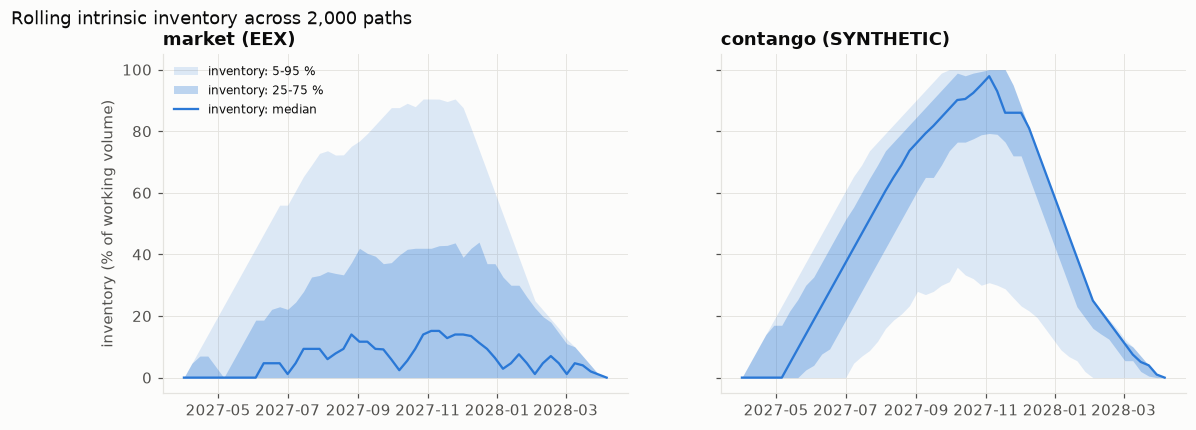

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, (inp, ri)) in zip(axes, ri_results.items(), strict=True):
    dates = inp.dates.append(pd.DatetimeIndex([inp.dates[-1] + pd.Timedelta(days=7)]))
    plotting.fan_chart(
        ax, dates, 100 * ri.inventory / inp.contract.working_volume, label="inventory"
    )
    ax.set_title(name)
axes[0].set_ylabel("inventory (% of working volume)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Rolling intrinsic inventory across 2,000 paths", x=0.01, ha="left")
plotting.save_figure(fig, "03_rolling_intrinsic_inventory")
fig

## 4. Findings

* **Market case (EEX, 2026-11-17).** Intrinsic value is exactly zero: every month of 2027/28 is cheaper than the
  previous one. The rolling intrinsic strategy is still worth a few MEUR (table above): when a simulated path moves
  the front of the curve up relative to later months, or the back up relative to the front, a spread opens and the
  monthly re-optimisation locks it. On this curve, **all of the storage value is extrinsic**.
* **Contango case (SYNTHETIC).** The intrinsic value is large and the optimal schedule has the familiar shape (fill
  in summer, hold, empty in winter, bent by the ratchets). Rolling intrinsic adds a smaller extrinsic increment on
  top of it.
* **Comparing the two cases.** The synthetic curve sits around 30 EUR/MWh, about half the market level of 2027/28.
  Under a lognormal model extrinsic value scales roughly with the price level, so the two cases should be compared
  through their *structure* (intrinsic vs extrinsic share), not through their amounts.
* **Why the increments are moderate.** With $\kappa \approx 4.8$ (half-life 53 days) forward volatility decays fast
  with maturity: seen from April 2027 the March 2028 forward barely moves (notebook 02). Monthly re-optimisation
  against forwards therefore leaves most of the *spot* optionality on the table; LSMC (notebook 04) captures it.
* **Numerics.** LP = DP without ratchets; DP converges to the MILP from below with ratchets (error $O(\Delta)$).
  Weekly steps evaluate ratchets at the start of the week, which is slightly more permissive than daily steps, so
  weekly intrinsic values are a little higher; daily values are the reference for the intrinsic, weekly steps are
  used for Monte Carlo speed.